(programmiamo-con-mpi)=
# Programmiamo con MPI

> **Senza eseguirlo:** il notebook è salvato con gli output dei run sul Mac. Si può leggere già eseguito [su GitHub](https://github.com/francescobellina/hpc4ai/blob/main/content/teoria/notebooks/programmiamo-con-mpi.ipynb) o [su nbviewer](https://nbviewer.org/github/francescobellina/hpc4ai/blob/main/content/teoria/notebooks/programmiamo-con-mpi.ipynb), senza aprirlo in VS Code.

Questo notebook mette in pratica il capitolo {ref}`t7-standard` e seguenti: scriviamo
piccoli programmi MPI in C, li compiliamo e li eseguiamo, e guardiamo cosa stampano.
Si parte da "chi sono?" e si arriva a un esempio completo, la **diffusione del calore
in 1D** con scambio degli halo, che usa quasi tutto quello che c'è nel capitolo.

**Come funziona ogni passo.**

1. Una cella `%%writefile` scrive il sorgente C in un file.
2. `compila("nome")` esegue `mpicc -O2 -Wall -Wextra nome.c -o nome`.
3. `mpirun(P, "./nome", ...)` lancia `P` processi e mostra l'output; se il programma
   non termina entro un tempo massimo, lo ferma (ci servirà per vedere un deadlock
   senza bloccare il notebook).

:::{note} Dove sono stati eseguiti
Gli output qui sotto sono quelli di un'esecuzione reale su un MacBook Pro con Apple
M3 Pro (6 core *performance* e 6 *efficiency*) e Open MPI 5.0.11 installato con
Homebrew: tutti i processi stanno sulla **stessa macchina**, quindi MPI comunica
attraverso la memoria condivisa, non attraverso una rete. Su WILSON lo stesso codice
si compila dopo `module load GCC/13.2.0 OpenMPI/4.1.6` e si lancia con `srun` invece
di `mpirun` (vedi la fine del notebook). I tempi misurati valgono per questa
macchina e per questo run.
:::

In [1]:
import os, signal, subprocess, tempfile, time
from pathlib import Path

# Cartella di lavoro temporanea per sorgenti ed eseguibili.
WORK = Path(tempfile.gettempdir()) / "programmiamo-con-mpi"
WORK.mkdir(exist_ok=True)
os.chdir(WORK)

# Evita un avviso del linker di macOS sulla versione minima del sistema.
os.environ["MACOSX_DEPLOYMENT_TARGET"] = subprocess.run(
    ["sw_vers", "-productVersion"], capture_output=True, text=True).stdout.strip()


def compila(nome):
    """Compila nome.c in ./nome con il wrapper di Open MPI."""
    cmd = ["mpicc", "-O2", "-Wall", "-Wextra", f"{nome}.c", "-o", nome, "-lm"]
    print("$", " ".join(cmd))
    r = subprocess.run(cmd, capture_output=True, text=True)
    print(r.stdout + r.stderr, end="")
    r.check_returncode()


def mpirun(n, *args, timeout=60):
    """Lancia `mpirun -n <n> <args>` e stampa l'output; ferma il job dopo `timeout` s."""
    cmd = ["mpirun", "-n", str(n), *map(str, args)]
    print("$", " ".join(cmd))
    p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                         text=True, start_new_session=True)
    try:
        out, _ = p.communicate(timeout=timeout)
        print(out, end="")
        return out
    except subprocess.TimeoutExpired:
        os.killpg(p.pid, signal.SIGTERM)       # ferma mpirun e tutti i suoi processi
        time.sleep(1)
        try:
            os.killpg(p.pid, signal.SIGKILL)
        except OSError:                        # il gruppo è già terminato
            pass
        out, _ = p.communicate()
        print(out, end="")
        print(f"[fermato dopo {timeout} s: il programma non è terminato]")
        return None


for c in (["mpicc", "--version"], ["mpirun", "--version"]):
    print(subprocess.run(c, capture_output=True, text=True).stdout.splitlines()[0])

Apple clang version 21.0.0 (clang-2100.1.1.101)
mpirun (Open MPI) 5.0.11


## 1. Chi sono? Il primo programma

**Idea.** `mpirun -n 4` avvia 4 copie dello **stesso** programma. Ogni copia chiede a
MPI il suo numero (il *rank*) e quanti processi ci sono in tutto: è il modello SPMD.
Con `MPI_Get_processor_name` chiede anche su quale macchina sta girando.

In [2]:
%%writefile hello.c
/* Ogni processo dice chi è: rank, numero di processi, macchina. */
#include <mpi.h>
#include <stdio.h>

int main(int argc, char **argv)
{
    MPI_Init(&argc, &argv);                     /* da qui si può usare MPI */

    int rank, size;
    MPI_Comm_rank(MPI_COMM_WORLD, &rank);       /* chi sono io: 0 ... size-1 */
    MPI_Comm_size(MPI_COMM_WORLD, &size);       /* quanti siamo in tutto     */

    char host[MPI_MAX_PROCESSOR_NAME];
    int len;
    MPI_Get_processor_name(host, &len);         /* su quale macchina giro    */

    printf("Hello from rank %d of %d su %s\n", rank, size, host);

    MPI_Finalize();                             /* tutti devono arrivare qui */
    return 0;
}

Writing hello.c


In [3]:
compila("hello")
mpirun(4, "./hello");

$ mpicc -O2 -Wall -Wextra hello.c -o hello -lm
$ mpirun -n 4 ./hello


Hello from rank 2 of 4 su MacBook-Pro-di-Francesco.local
Hello from rank 0 of 4 su MacBook-Pro-di-Francesco.local
Hello from rank 1 of 4 su MacBook-Pro-di-Francesco.local
Hello from rank 3 of 4 su MacBook-Pro-di-Francesco.local


**Cosa osserviamo.** Quattro righe, una per processo, ma **non in ordine di rank**
(qui 2, 0, 1, 3): i processi girano indipendenti e `mpirun` stampa le righe man mano
che arrivano. Rieseguendo la cella l'ordine può cambiare. Tutti dicono lo stesso
`size` e la stessa macchina: su un portatile tutti i rank stanno sullo stesso
computer, su WILSON qui comparirebbe il nome del nodo (`wnode..`).

## 2. Point-to-point: un testimone che fa il giro

**Idea.** I processi non condividono variabili: per passare un valore bisogna
**spedirlo**. Qui un intero (il "testimone") parte dal rank 0, passa per tutti i rank
in ordine e torna al rank 0. Ogni rank lo riceve dal precedente con `MPI_Recv`, ci
somma il proprio numero e lo spedisce al successivo con `MPI_Send`. Alla fine il
testimone vale $0 + 1 + \dots + (P-1) = P(P-1)/2$.

Il rank 0 deve **prima** spedire e **poi** ricevere; tutti gli altri il contrario.
Se anche il rank 0 cominciasse con `MPI_Recv`, tutti aspetterebbero un messaggio che
nessuno ha mandato.

In [4]:
%%writefile anello.c
/* Un "testimone" fa il giro dei rank: 0 -> 1 -> ... -> size-1 -> 0.
   Ogni rank aggiunge il proprio numero e lo passa al successivo. */
#include <mpi.h>
#include <stdio.h>

int main(int argc, char **argv)
{
    MPI_Init(&argc, &argv);
    int rank, size;
    MPI_Comm_rank(MPI_COMM_WORLD, &rank);
    MPI_Comm_size(MPI_COMM_WORLD, &size);

    int next = (rank + 1) % size;               /* a chi passo il testimone */
    int prev = (rank - 1 + size) % size;        /* da chi lo ricevo         */
    int token;

    if (rank == 0) {
        token = 0;                              /* il rank 0 parte          */
        MPI_Send(&token, 1, MPI_INT, next, 0, MPI_COMM_WORLD);
        MPI_Recv(&token, 1, MPI_INT, prev, 0, MPI_COMM_WORLD, MPI_STATUS_IGNORE);
        printf("rank 0: il testimone è tornato con valore %d (atteso %d)\n",
               token, size * (size - 1) / 2);
    } else {
        MPI_Recv(&token, 1, MPI_INT, prev, 0, MPI_COMM_WORLD, MPI_STATUS_IGNORE);
        printf("rank %d: ricevo %d dal rank %d, passo %d al rank %d\n",
               rank, token, prev, token + rank, next);
        token += rank;
        MPI_Send(&token, 1, MPI_INT, next, 0, MPI_COMM_WORLD);
    }

    MPI_Finalize();
    return 0;
}

Writing anello.c


In [5]:
compila("anello")
mpirun(4, "./anello")
mpirun(6, "./anello");

$ mpicc -O2 -Wall -Wextra anello.c -o anello -lm
$ mpirun -n 4 ./anello
rank 1: ricevo 0 dal rank 0, passo 1 al rank 2
rank 2: ricevo 1 dal rank 1, passo 3 al rank 3
rank 3: ricevo 3 dal rank 2, passo 6 al rank 0
rank 0: il testimone è tornato con valore 6 (atteso 6)
$ mpirun -n 6 ./anello


rank 1: ricevo 0 dal rank 0, passo 1 al rank 2
rank 2: ricevo 1 dal rank 1, passo 3 al rank 3
rank 3: ricevo 3 dal rank 2, passo 6 al rank 4
rank 4: ricevo 6 dal rank 3, passo 10 al rank 5
rank 5: ricevo 10 dal rank 4, passo 15 al rank 0
rank 0: il testimone è tornato con valore 15 (atteso 15)


**Cosa osserviamo.** Il testimone torna al rank 0 con 6 per 4 processi e 15 per 6,
come previsto da $P(P-1)/2$. Questa volta le righe escono **in ordine**: non perché
`mpirun` le ordini, ma perché ogni rank può stampare solo dopo aver ricevuto il
messaggio dal precedente. È la comunicazione a imporre l'ordine.

## 3. Scambiare dati: bloccante, `Sendrecv` e non bloccante

**Idea.** Ora due rank si scambiano `n` double **contemporaneamente**. Il programma
fa lo stesso scambio in tre modi, scelti dal primo argomento:

- `bloccante`: entrambi fanno `MPI_Send` e poi `MPI_Recv`, l'ordine "ingenuo" che
  rischia il deadlock ({ref}`t7-deadlock`);
- `sendrecv`: una sola chiamata `MPI_Sendrecv`;
- `nonbloccante`: `MPI_Irecv`, `MPI_Isend`, poi `MPI_Waitall`
  ({ref}`t7-confronto`).

Ogni rank riempie il suo buffer con il proprio numero, quindi ognuno deve ricevere il
numero dell'altro.

In [6]:
%%writefile scambio.c
/* Due rank si scambiano n double in tre modi diversi. */
#include <mpi.h>
#include <stdio.h>
#include <stdlib.h>
#include <string.h>

int main(int argc, char **argv)
{
    MPI_Init(&argc, &argv);
    int rank, size;
    MPI_Comm_rank(MPI_COMM_WORLD, &rank);
    MPI_Comm_size(MPI_COMM_WORLD, &size);
    if (size != 2) {
        if (rank == 0) fprintf(stderr, "Serve esattamente 2 rank\n");
        MPI_Abort(MPI_COMM_WORLD, 1);
    }

    const char *modo = argv[1];          /* bloccante | sendrecv | nonbloccante */
    int n = atoi(argv[2]);               /* numero di double da scambiare      */
    double *sendbuf = malloc(n * sizeof(double));
    double *recvbuf = malloc(n * sizeof(double));
    for (int i = 0; i < n; ++i) sendbuf[i] = rank;   /* ogni rank manda il suo numero */

    int peer = 1 - rank;                 /* 0 <-> 1 */
    if (strcmp(modo, "bloccante") == 0) {
        MPI_Send(sendbuf, n, MPI_DOUBLE, peer, 0, MPI_COMM_WORLD);
        MPI_Recv(recvbuf, n, MPI_DOUBLE, peer, 0, MPI_COMM_WORLD, MPI_STATUS_IGNORE);
    } else if (strcmp(modo, "sendrecv") == 0) {
        MPI_Sendrecv(sendbuf, n, MPI_DOUBLE, peer, 0,
                     recvbuf, n, MPI_DOUBLE, peer, 0,
                     MPI_COMM_WORLD, MPI_STATUS_IGNORE);
    } else {
        MPI_Request req[2];
        MPI_Irecv(recvbuf, n, MPI_DOUBLE, peer, 0, MPI_COMM_WORLD, &req[0]);
        MPI_Isend(sendbuf, n, MPI_DOUBLE, peer, 0, MPI_COMM_WORLD, &req[1]);
        MPI_Waitall(2, req, MPI_STATUSES_IGNORE);
    }
    printf("rank %d (%s, n = %d): ricevuto %.0f dal rank %d\n", rank, modo, n, recvbuf[n - 1], peer);

    free(sendbuf); free(recvbuf);
    MPI_Finalize();
    return 0;
}

Writing scambio.c


In [7]:
compila("scambio")
mpirun(2, "./scambio", "bloccante", 100)
mpirun(2, "./scambio", "bloccante", 1000, timeout=5);

$ mpicc -O2 -Wall -Wextra scambio.c -o scambio -lm
$ mpirun -n 2 ./scambio bloccante 100


rank 1 (bloccante, n = 100): ricevuto 0 dal rank 0
rank 0 (bloccante, n = 100): ricevuto 1 dal rank 1
$ mpirun -n 2 ./scambio bloccante 1000


[fermato dopo 5 s: il programma non è terminato]


**Cosa osserviamo.** Con 100 double (800 byte) lo scambio ingenuo funziona; con 1000
double (8000 byte) il programma resta fermo finché il notebook non lo interrompe dopo
5 secondi. È il deadlock della slide: entrambi i rank sono dentro `MPI_Send` e
nessuno arriva alla sua `MPI_Recv`. Lo stesso codice, cambiando solo la dimensione
del messaggio, funziona o si blocca.

### Dove sta la soglia?

Cerchiamo per bisezione il più piccolo `n` per cui lo scambio bloccante si blocca
(ogni tentativo ha 3 secondi di tempo). Le uscite dei singoli tentativi non vengono
stampate.

In [8]:
import contextlib, io

lo, hi = 100, 1000                 # 100 funziona, 1000 si blocca
while hi - lo > 1:
    mid = (lo + hi) // 2
    with contextlib.redirect_stdout(io.StringIO()):
        funziona = mpirun(2, "./scambio", "bloccante", mid, timeout=3) is not None
    lo, hi = (mid, hi) if funziona else (lo, mid)

print(f"funziona fino a n = {lo} double ({8 * lo} byte), si blocca da n = {hi} ({8 * hi} byte)")

funziona fino a n = 502 double (4016 byte), si blocca da n = 503 (4024 byte)


Il numero non è casuale. Open MPI ha un parametro che dice fino a quale dimensione un
messaggio fra processi della stessa macchina viene spedito subito (protocollo
*eager*): il mittente lo copia in un buffer e `MPI_Send` torna senza aspettare il
destinatario. Sopra quella soglia la send aspetta che il destinatario sia pronto
(protocollo *rendezvous*), e nello scambio ingenuo nessuno dei due lo è mai.

In [9]:
print(subprocess.run("ompi_info --param btl sm --level 9 | grep 'btl_sm_eager_limit'",
                     shell=True, capture_output=True, text=True).stdout)

              MCA btl sm: parameter "btl_sm_eager_limit" (current value: "4096", data source: default, level: 4 tuner/basic, type: size_t, synonyms: btl_vader_eager_limit)



Il limite è 4096 byte **compresa l'intestazione** del messaggio, quindi un po' meno
di 4096 byte di dati. Se è davvero questo il meccanismo, alzando il limite lo scambio
ingenuo deve funzionare anche con 1000 double (8000 byte), e bloccarsi di nuovo con
un messaggio più grande del nuovo limite:

In [10]:
mpirun(2, "--mca", "btl_sm_eager_limit", 16384, "./scambio", "bloccante", 1000, timeout=5)
mpirun(2, "--mca", "btl_sm_eager_limit", 16384, "./scambio", "bloccante", 3000, timeout=5);

$ mpirun -n 2 --mca btl_sm_eager_limit 16384 ./scambio bloccante 1000
rank 1 (bloccante, n = 1000): ricevuto 0 dal rank 0
rank 0 (bloccante, n = 1000): ricevuto 1 dal rank 1
$ mpirun -n 2 --mca btl_sm_eager_limit 16384 ./scambio bloccante 3000


[fermato dopo 5 s: il programma non è terminato]


È la dimostrazione pratica della slide sul deadlock: **un test con messaggi piccoli
che funziona non prova che l'ordine sia sicuro**, perché il risultato dipende da un
parametro interno dell'implementazione, che su WILSON o fra nodi diversi può avere
un altro valore.

Le due versioni corrette funzionano anche con un milione di double (8 MB):

In [11]:
mpirun(2, "./scambio", "sendrecv", 1_000_000)
mpirun(2, "./scambio", "nonbloccante", 1_000_000);

$ mpirun -n 2 ./scambio sendrecv 1000000
rank 1 (sendrecv, n = 1000000): ricevuto 0 dal rank 0
rank 0 (sendrecv, n = 1000000): ricevuto 1 dal rank 1
$ mpirun -n 2 ./scambio nonbloccante 1000000
rank 1 (nonbloccante, n = 1000000): ricevuto 0 dal rank 0
rank 0 (nonbloccante, n = 1000000): ricevuto 1 dal rank 1


## 4. Collettive: calcolare π in parallelo

**Idea.** $\pi = \int_0^1 \frac{4}{1+x^2}\,dx$. Con la regola del punto medio su
$n$ intervalli l'integrale diventa una somma di $n$ termini, e ogni rank può sommare
il suo blocco di intervalli. Servono due collettive:

- `MPI_Bcast`: solo il rank 0 legge $n$ dalla riga di comando e lo manda a tutti;
- `MPI_Reduce` con `MPI_SUM`: le somme parziali diventano $\pi$ sul rank 0.

I blocchi seguono la regola $n = qP + r$ di {ref}`t7-decomposizione`. Il tempo è
misurato con `MPI_Wtime` su ogni rank e ridotto con `MPI_MAX`, come nella sezione
{ref}`t7-prestazioni`.

In [12]:
%%writefile pi.c
/* pi = integrale fra 0 e 1 di 4 / (1 + x^2), regola del punto medio con n intervalli.
   Il rank 0 sceglie n e lo manda a tutti (MPI_Bcast); ogni rank somma il suo blocco
   di intervalli; MPI_Reduce somma i pezzi sul rank 0. */
#include <math.h>
#include <mpi.h>
#include <stdio.h>
#include <stdlib.h>

int main(int argc, char **argv)
{
    MPI_Init(&argc, &argv);
    int rank, size;
    MPI_Comm_rank(MPI_COMM_WORLD, &rank);
    MPI_Comm_size(MPI_COMM_WORLD, &size);

    long n = 0;
    if (rank == 0) n = atol(argv[1]);           /* solo il rank 0 legge l'input */
    MPI_Bcast(&n, 1, MPI_LONG, 0, MPI_COMM_WORLD);

    /* Decomposizione a blocchi: n = q*size + r, i primi r rank hanno un intervallo in più. */
    long q = n / size, r = n % size;
    long count = q + (rank < r ? 1 : 0);
    long start = rank * q + (rank < r ? rank : r);

    MPI_Barrier(MPI_COMM_WORLD);                /* partenza comune per la misura */
    double t0 = MPI_Wtime();

    double h = 1.0 / n, local = 0.0;
    for (long i = start; i < start + count; ++i) {
        double x = (i + 0.5) * h;
        local += 4.0 / (1.0 + x * x);
    }
    local *= h;

    double pi;
    MPI_Reduce(&local, &pi, 1, MPI_DOUBLE, MPI_SUM, 0, MPI_COMM_WORLD);

    double t_local = MPI_Wtime() - t0, t_max;
    MPI_Reduce(&t_local, &t_max, 1, MPI_DOUBLE, MPI_MAX, 0, MPI_COMM_WORLD);

    if (rank == 0)
        printf("P = %d  pi = %.15f  errore = %.1e  tempo = %.3f s\n",
               size, pi, fabs(pi - M_PI), t_max);

    MPI_Finalize();
    return 0;
}

Writing pi.c


In [13]:
compila("pi")
risultati = {}
for P in (1, 2, 4, 6, 8):
    out = mpirun(P, "./pi", 400_000_000)
    risultati[P] = float(out.split("tempo =")[1].split()[0])

$ mpicc -O2 -Wall -Wextra pi.c -o pi -lm


$ mpirun -n 1 ./pi 400000000


P = 1  pi = 3.141592653589552  errore = 2.4e-13  tempo = 0.282 s
$ mpirun -n 2 ./pi 400000000


P = 2  pi = 3.141592653590022  errore = 2.3e-13  tempo = 0.144 s
$ mpirun -n 4 ./pi 400000000
P = 4  pi = 3.141592653590041  errore = 2.5e-13  tempo = 0.078 s
$ mpirun -n 6 ./pi 400000000


P = 6  pi = 3.141592653589910  errore = 1.2e-13  tempo = 0.053 s
$ mpirun -n 8 ./pi 400000000
P = 8  pi = 3.141592653589885  errore = 9.1e-14  tempo = 0.044 s


In [14]:
import pandas as pd

t1 = risultati[1]
tab = pd.DataFrame({"P": list(risultati), "tempo (s)": list(risultati.values())})
tab["speedup"] = t1 / tab["tempo (s)"]
tab["efficienza"] = tab["speedup"] / tab["P"]
tab.round(3)

,P,tempo (s),speedup,efficienza
0,1,0.282,1.000,1.000
1,2,0.144,1.958,0.979
2,4,0.078,3.615,0.904
3,6,0.053,5.321,0.887
4,8,0.044,6.409,0.801


**Cosa osserviamo.**

- Lo speedup è quasi ideale fino a 6 processi (efficienza 0.98 con 2, 0.89 con 6):
  ogni rank lavora solo sui suoi intervalli e comunica una volta sola alla fine.
- Con 8 processi l'efficienza scende a 0.80. Il Mac ha 6 core *performance* e 6
  *efficiency*: con più di 6 processi alcuni finiscono su core più lenti, e il tempo
  misurato con `MPI_MAX` è quello del rank più lento. È un'interpretazione
  plausibile, non verificata guardando su quali core sono finiti i processi.
- Il valore di π **cambia nelle ultime cifre** con $P$ (…589552 con 1 processo,
  …590022 con 2, …590041 con 4): con $P$ diverso le somme parziali e la riduzione
  sommano gli stessi termini in un ordine diverso, e la somma in virgola mobile non
  è associativa. L'errore di discretizzazione della regola del punto medio, con
  $h = 2.5\times10^{-9}$, è dell'ordine di $h^2 \approx 6\times10^{-18}$: l'errore
  di circa $10^{-13}$ viene dagli arrotondamenti, non dal metodo.

## 5. Dividere un array: `MPI_Scatterv` e `MPI_Gatherv`

**Idea.** Il rank 0 ha un array di $N = 10$ interi. Con `MPI_Scatterv` ogni rank ne
riceve un blocco (di dimensioni diverse, perché 10 non si divide per 3), lo eleva al
quadrato, e `MPI_Gatherv` rimette insieme i pezzi sul rank 0 nell'ordine giusto.
Conteggi e spostamenti li calcola ogni rank con la stessa regola.

In [15]:
%%writefile scatterv.c
/* Il rank 0 ha un array di N elementi; MPI_Scatterv ne dà un blocco a ogni rank,
   ognuno lo eleva al quadrato, MPI_Gatherv rimette insieme il risultato. */
#include <mpi.h>
#include <stdio.h>
#include <stdlib.h>

int main(int argc, char **argv)
{
    MPI_Init(&argc, &argv);
    int rank, size;
    MPI_Comm_rank(MPI_COMM_WORLD, &rank);
    MPI_Comm_size(MPI_COMM_WORLD, &size);

    const int N = 10;
    /* Tutti calcolano conteggi e spostamenti con la regola N = q*size + r. */
    int *counts = malloc(size * sizeof(int)), *displs = malloc(size * sizeof(int));
    int q = N / size, r = N % size;
    for (int p = 0; p < size; ++p) {
        counts[p] = q + (p < r ? 1 : 0);
        displs[p] = p * q + (p < r ? p : r);
    }

    int global[10], result[10];                 /* significativi solo sul rank 0 */
    if (rank == 0)
        for (int i = 0; i < N; ++i) global[i] = i;

    int local[10];
    MPI_Scatterv(global, counts, displs, MPI_INT,
                 local, counts[rank], MPI_INT, 0, MPI_COMM_WORLD);

    printf("rank %d: indici globali [%d, %d), ricevo", rank, displs[rank], displs[rank] + counts[rank]);
    for (int i = 0; i < counts[rank]; ++i) printf(" %d", local[i]);
    printf("\n");

    for (int i = 0; i < counts[rank]; ++i) local[i] *= local[i];   /* lavoro locale */

    MPI_Gatherv(local, counts[rank], MPI_INT,
                result, counts, displs, MPI_INT, 0, MPI_COMM_WORLD);

    if (rank == 0) {
        printf("rank 0 dopo il gather:");
        for (int i = 0; i < N; ++i) printf(" %d", result[i]);
        printf("\n");
    }

    free(counts); free(displs);
    MPI_Finalize();
    return 0;
}

Writing scatterv.c


In [16]:
compila("scatterv")
mpirun(3, "./scatterv")
mpirun(4, "./scatterv");

$ mpicc -O2 -Wall -Wextra scatterv.c -o scatterv -lm
$ mpirun -n 3 ./scatterv


rank 0: indici globali [0, 4), ricevo 0 1 2 3
rank 1: indici globali [4, 7), ricevo 4 5 6
rank 2: indici globali [7, 10), ricevo 7 8 9
rank 0 dopo il gather: 0 1 4 9 16 25 36 49 64 81
$ mpirun -n 4 ./scatterv


rank 0: indici globali [0, 3), ricevo 0 1 2
rank 2: indici globali [6, 8), ricevo 6 7
rank 3: indici globali [8, 10), ricevo 8 9
rank 1: indici globali [3, 6), ricevo 3 4 5
rank 0 dopo il gather: 0 1 4 9 16 25 36 49 64 81


**Cosa osserviamo.** Con 3 rank i blocchi sono 4, 3, 3 (intervalli $[0,4)$,
$[4,7)$, $[7,10)$), esattamente l'esempio della decomposizione a blocchi; con 4 rank
sono 3, 3, 2, 2. Le righe dei singoli rank possono uscire in disordine, ma
`MPI_Gatherv` rimette i pezzi al loro posto: il rank 0 ottiene sempre
`0 1 4 9 16 25 36 49 64 81`, qualunque sia il numero di processi.

## 6. Sottogruppi: `MPI_Comm_split`

**Idea.** `MPI_Comm_split` divide i rank in gruppi con lo stesso `colour`: qui pari e
dispari. Ogni gruppo è un nuovo communicator con i suoi rank (da 0) e può fare
collettive per conto suo: ognuno calcola la somma dei world rank del proprio gruppo
con `MPI_Allreduce`.

In [17]:
%%writefile split.c
/* MPI_Comm_split divide i rank in pari e dispari; ogni gruppo fa la sua somma. */
#include <mpi.h>
#include <stdio.h>

int main(int argc, char **argv)
{
    MPI_Init(&argc, &argv);
    int world_rank;
    MPI_Comm_rank(MPI_COMM_WORLD, &world_rank);

    int colour = world_rank % 2;                /* 0 = pari, 1 = dispari */
    MPI_Comm group;
    MPI_Comm_split(MPI_COMM_WORLD, colour, world_rank, &group);

    int group_rank, group_size;
    MPI_Comm_rank(group, &group_rank);
    MPI_Comm_size(group, &group_size);

    int sum;                                    /* somma dei world rank del mio gruppo */
    MPI_Allreduce(&world_rank, &sum, 1, MPI_INT, MPI_SUM, group);

    printf("world rank %d: gruppo %s, rank %d di %d nel gruppo, somma del gruppo = %d\n",
           world_rank, colour ? "dispari" : "pari", group_rank, group_size, sum);

    MPI_Comm_free(&group);
    MPI_Finalize();
    return 0;
}

Writing split.c


In [18]:
compila("split")
mpirun(4, "./split");

$ mpicc -O2 -Wall -Wextra split.c -o split -lm
$ mpirun -n 4 ./split


world rank 1: gruppo dispari, rank 0 di 2 nel gruppo, somma del gruppo = 4
world rank 2: gruppo pari, rank 1 di 2 nel gruppo, somma del gruppo = 2
world rank 0: gruppo pari, rank 0 di 2 nel gruppo, somma del gruppo = 2
world rank 3: gruppo dispari, rank 1 di 2 nel gruppo, somma del gruppo = 4


**Cosa osserviamo.** I world rank 0 e 2 formano il gruppo pari e diventano i rank 0 e
1 del nuovo communicator; lo stesso per 1 e 3 nel gruppo dispari, come nella tabella
del capitolo. Ogni `MPI_Allreduce` coinvolge solo il proprio gruppo: la somma vale
$0 + 2 = 2$ per i pari e $1 + 3 = 4$ per i dispari.

## 7. Tipi derivati: spedire una colonna

**Idea.** In `double a[4][6]` la colonna 2 non è contigua in memoria: i suoi
elementi distano 6 double. `MPI_Type_vector(4, 1, 6, MPI_DOUBLE, ...)` la descrive
(4 blocchi da 1 elemento, passo 6) e il rank 0 la spedisce con una sola `MPI_Send`.
Il rank 1 la riceve come 4 double contigui. Per riconoscere gli elementi, `a[i][j]`
vale $10\,i + j$.

In [19]:
%%writefile colonna.c
/* Il rank 0 manda la colonna 2 di double a[4][6] con un tipo derivato;
   il rank 1 la riceve come 4 double contigui. */
#include <mpi.h>
#include <stdio.h>

int main(int argc, char **argv)
{
    MPI_Init(&argc, &argv);
    int rank;
    MPI_Comm_rank(MPI_COMM_WORLD, &rank);

    if (rank == 0) {
        double a[4][6];
        for (int i = 0; i < 4; ++i)
            for (int j = 0; j < 6; ++j) a[i][j] = 10 * i + j;   /* a[i][j] = "ij" */

        MPI_Datatype column;
        MPI_Type_vector(4, 1, 6, MPI_DOUBLE, &column);  /* 4 blocchi da 1, passo 6 */
        MPI_Type_commit(&column);
        MPI_Send(&a[0][2], 1, column, 1, 0, MPI_COMM_WORLD);
        MPI_Type_free(&column);
    } else if (rank == 1) {
        double col[4];
        MPI_Recv(col, 4, MPI_DOUBLE, 0, 0, MPI_COMM_WORLD, MPI_STATUS_IGNORE);
        printf("rank 1 riceve la colonna 2: %g %g %g %g\n", col[0], col[1], col[2], col[3]);
    }

    MPI_Finalize();
    return 0;
}

Writing colonna.c


In [20]:
compila("colonna")
mpirun(2, "./colonna");

$ mpicc -O2 -Wall -Wextra colonna.c -o colonna -lm
$ mpirun -n 2 ./colonna
rank 1 riceve la colonna 2: 2 12 22 32


**Cosa osserviamo.** Il rank 1 riceve `2 12 22 32`, cioè `a[0][2]`, `a[1][2]`,
`a[2][2]`, `a[3][2]`: il tipo derivato ha preso un elemento ogni 6, partendo da
`&a[0][2]`, senza che il programma copiasse la colonna in un buffer. Chi riceve non
ha bisogno dello stesso tipo: gli bastano 4 double contigui.

## 8. L'esempio completo: diffusione del calore in 1D

**Il problema.** Una sbarra divisa in $N$ celle, con le due estremità tenute a
temperatura 0 e un punto caldo al centro (4 celle a 100). A ogni passo ogni cella si
avvicina alla media delle vicine:

$$u_i^{\text{nuovo}} = u_i + \alpha\,(u_{i-1} - 2u_i + u_{i+1}), \qquad \alpha = 0.25.$$

**Come lo dividiamo.** Ogni rank possiede un blocco di celle consecutive. Per
aggiornare la sua prima e la sua ultima cella gli serve un valore del vicino: per
questo ha due **celle fantasma** (`u[0]` e `u[n+1]`) che a ogni passo riempie con
uno scambio di halo ({ref}`t7-datatype`). Il programma usa:

| Passo | Chiamate MPI |
|---|---|
| linea di processi e vicini | `MPI_Cart_create`, `MPI_Cart_shift` (`MPI_PROC_NULL` agli estremi) |
| divisione delle celle | regola $N = qP + r$ |
| scambio degli halo | `MPI_Irecv` ×2, `MPI_Isend` ×2, `MPI_Waitall` |
| profilo completo sul rank 0 | `MPI_Gatherv` |
| calore totale | `MPI_Reduce` con `MPI_SUM` |
| tempi di calcolo e comunicazione | `MPI_Wtime`, `MPI_Reduce` con `MPI_MAX` |

Agli estremi il vicino è `MPI_PROC_NULL`: lo scambio non trasferisce nulla e la cella
fantasma resta a 0, che è proprio la condizione al contorno. Il programma usa due
array, `u` e `u_new`, e a ogni passo ne scambia i ruoli.

In [21]:
%%writefile calore.c
/* Diffusione del calore in 1D con MPI.
   u_nuovo[i] = u[i] + alpha * (u[i-1] - 2 u[i] + u[i+1]),  bordi fissi a 0.
   Ogni rank possiede un blocco di celle e due celle fantasma (halo);
   a ogni passo scambia i bordi con i vicini e aggiorna il suo blocco.

   Uso: calore N passi [file.csv]
   Con file.csv il rank 0 scrive il profilo completo ogni passi/4 passi;
   senza, il programma misura solo i tempi di calcolo e di comunicazione. */
#include <mpi.h>
#include <stdio.h>
#include <stdlib.h>

int main(int argc, char **argv)
{
    MPI_Init(&argc, &argv);
    int size;
    MPI_Comm_size(MPI_COMM_WORLD, &size);

    int N = atoi(argv[1]), steps = atoi(argv[2]);
    const char *csv = argc > 3 ? argv[3] : NULL;
    const double alpha = 0.25;                  /* stabile per alpha <= 0.5 */

    /* 1. Topologia: una linea non periodica di processi. */
    int dims[1] = {size}, periods[1] = {0};
    MPI_Comm line;
    MPI_Cart_create(MPI_COMM_WORLD, 1, dims, periods, 1, &line);
    int rank, left, right;
    MPI_Comm_rank(line, &rank);
    MPI_Cart_shift(line, 0, 1, &left, &right); /* MPI_PROC_NULL ai bordi */

    /* 2. Decomposizione a blocchi: N = q*size + r. */
    int *counts = malloc(size * sizeof(int)), *displs = malloc(size * sizeof(int));
    int q = N / size, r = N % size;
    for (int p = 0; p < size; ++p) {
        counts[p] = q + (p < r ? 1 : 0);
        displs[p] = p * q + (p < r ? p : r);
    }
    int n = counts[rank];                       /* celle mie: u[1] ... u[n] */

    /* 3. Array locali con 2 celle fantasma, tutti a zero (anche i bordi fisici). */
    double *u = calloc(n + 2, sizeof(double)), *u_new = calloc(n + 2, sizeof(double));
    for (int i = 1; i <= n; ++i) {
        int g = displs[rank] + i - 1;           /* indice globale della cella i */
        if (g >= N / 2 - 2 && g < N / 2 + 2) u[i] = 100.0;   /* punto caldo al centro */
    }

    if (csv) {
        char ls[16] = "nessuno", rs[16] = "nessuno";
        if (left != MPI_PROC_NULL) snprintf(ls, sizeof ls, "rank %d", left);
        if (right != MPI_PROC_NULL) snprintf(rs, sizeof rs, "rank %d", right);
        printf("rank %d: celle globali [%d, %d), vicino sinistro %s, vicino destro %s\n",
               rank, displs[rank], displs[rank] + n, ls, rs);
    }

    double *global = rank == 0 ? malloc(N * sizeof(double)) : NULL;
    FILE *out = (csv && rank == 0) ? fopen(csv, "w") : NULL;
    if (out) fprintf(out, "passo,cella,u\n");
    double t_comm = 0.0, t_comp = 0.0;
    enum { TAG_TO_LEFT = 0, TAG_TO_RIGHT = 1 };

    for (int s = 0; s <= steps; ++s) {
        /* Ogni steps/4 passi: raccolta del profilo sul rank 0 e calore totale. */
        if (csv && s % (steps / 4) == 0) {
            MPI_Gatherv(&u[1], n, MPI_DOUBLE, global, counts, displs, MPI_DOUBLE, 0, line);
            double local_heat = 0.0, heat;
            for (int i = 1; i <= n; ++i) local_heat += u[i];
            MPI_Reduce(&local_heat, &heat, 1, MPI_DOUBLE, MPI_SUM, 0, line);
            if (rank == 0) {
                printf("passo %5d: calore totale = %.6f\n", s, heat);
                for (int g = 0; g < N; ++g) fprintf(out, "%d,%d,%.17g\n", s, g, global[g]);
            }
        }
        if (s == steps) break;

        /* 4. Scambio degli halo: prima le ricezioni, poi gli invii, poi l'attesa. */
        double t0 = MPI_Wtime();
        MPI_Request req[4];
        MPI_Irecv(&u[0],     1, MPI_DOUBLE, left,  TAG_TO_RIGHT, line, &req[0]);
        MPI_Irecv(&u[n + 1], 1, MPI_DOUBLE, right, TAG_TO_LEFT,  line, &req[1]);
        MPI_Isend(&u[1],     1, MPI_DOUBLE, left,  TAG_TO_LEFT,  line, &req[2]);
        MPI_Isend(&u[n],     1, MPI_DOUBLE, right, TAG_TO_RIGHT, line, &req[3]);
        MPI_Waitall(4, req, MPI_STATUSES_IGNORE);
        double t1 = MPI_Wtime();

        /* 5. Aggiornamento: legge u (con gli halo freschi), scrive u_new. */
        for (int i = 1; i <= n; ++i)
            u_new[i] = u[i] + alpha * (u[i - 1] - 2.0 * u[i] + u[i + 1]);
        double *tmp = u; u = u_new; u_new = tmp;   /* le due griglie si scambiano i ruoli */
        t_comp += MPI_Wtime() - t1;
        t_comm += t1 - t0;
    }

    if (!csv) {                                 /* solo misura dei tempi */
        double comm, comp;
        MPI_Reduce(&t_comm, &comm, 1, MPI_DOUBLE, MPI_MAX, 0, line);
        MPI_Reduce(&t_comp, &comp, 1, MPI_DOUBLE, MPI_MAX, 0, line);
        if (rank == 0)
            printf("N = %8d  P = %d  celle per rank = %7d  calcolo = %.4f s  comunicazione = %.4f s  (%2.0f%%)\n",
                   N, size, N / size, comp, comm, 100.0 * comm / (comm + comp));
    }

    if (out) fclose(out);
    free(global); free(u); free(u_new); free(counts); free(displs);
    MPI_Comm_free(&line);
    MPI_Finalize();
    return 0;
}

Writing calore.c


In [22]:
compila("calore")
mpirun(1, "./calore", 60, 400, "calore_P1.csv")
mpirun(4, "./calore", 60, 400, "calore_P4.csv");

$ mpicc -O2 -Wall -Wextra calore.c -o calore -lm


$ mpirun -n 1 ./calore 60 400 calore_P1.csv


rank 0: celle globali [0, 60), vicino sinistro nessuno, vicino destro nessuno
passo     0: calore totale = 400.000000
passo   100: calore totale = 399.985178
passo   200: calore totale = 398.060403
passo   300: calore totale = 389.481585
passo   400: calore totale = 374.720599
$ mpirun -n 4 ./calore 60 400 calore_P4.csv
rank 3: celle globali [45, 60), vicino sinistro rank 2, vicino destro nessuno
rank 0: celle globali [0, 15), vicino sinistro nessuno, vicino destro rank 1
rank 1: celle globali [15, 30), vicino sinistro rank 0, vicino destro rank 2
rank 2: celle globali [30, 45), vicino sinistro rank 1, vicino destro rank 3
passo     0: calore totale = 400.000000
passo   100: calore totale = 399.985178
passo   200: calore totale = 398.060403
passo   300: calore totale = 389.481585
passo   400: calore totale = 374.720599


**Cosa osserviamo.** Con 4 rank ognuno possiede 15 celle; il rank 0 non ha vicino a
sinistra e il rank 3 non ne ha a destra (`MPI_Cart_shift` ha restituito
`MPI_PROC_NULL`). Il calore totale è **lo stesso** con 1 e 4 processi a ogni passo
stampato. Resta 400 all'inizio, poi cala: quando il calore arriva alle estremità,
tenute a 0, esce dalla sbarra.

**Il controllo più importante.** Il risultato parallelo deve essere uguale a quello
seriale. Qui non ci sono riduzioni in virgola mobile nel calcolo (ogni cella fa le
stesse operazioni nello stesso ordine), quindi ci aspettiamo profili **identici bit
per bit**:

In [23]:
p1 = pd.read_csv("calore_P1.csv")
p4 = pd.read_csv("calore_P4.csv")
print("massima differenza fra P = 1 e P = 4:", (p1.u - p4.u).abs().max())

massima differenza fra P = 1 e P = 4: 0.0


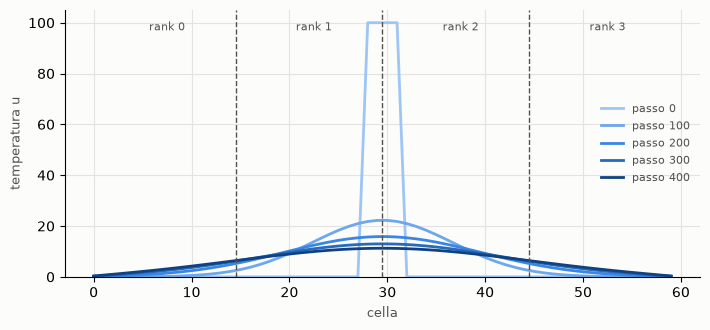

In [24]:
import matplotlib.pyplot as plt

SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
RAMPA = ["#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#104281"]   # un solo colore, dal chiaro allo scuro

fig, ax = plt.subplots(figsize=(7.2, 3.4), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.grid(color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for colore, (passo, g) in zip(RAMPA, p4.groupby("passo")):
    ax.plot(g.cella, g.u, color=colore, linewidth=2, label=f"passo {passo}")
for confine in (15, 30, 45):                          # confini fra i 4 rank
    ax.axvline(confine - 0.5, color=INK2, linewidth=1, linestyle="--")
for r in range(4):
    ax.text(7.5 + 15 * r, 97, f"rank {r}", ha="center", fontsize=8, color=INK2)
ax.set_xlabel("cella", color=INK2, fontsize=9)
ax.set_ylabel("temperatura u", color=INK2, fontsize=9)
ax.set_ylim(0, 105)
ax.legend(fontsize=8, frameon=False, labelcolor=INK2)
fig.tight_layout()
plt.show()

**Cosa osserviamo.** La differenza fra 1 e 4 processi è esattamente 0: la versione
parallela fa gli stessi conti della seriale. Nel grafico il punto caldo si allarga e
si abbassa passo dopo passo, e i profili attraversano i confini fra i rank (linee
tratteggiate) senza scalini. Se gli halo non venissero scambiati, ogni rank vedrebbe
il vicino come se fosse a temperatura 0 e il calore non passerebbe da un blocco
all'altro.

### Quanto costa comunicare?

**Idea.** In 1D ogni rank scambia sempre 2 valori per passo, qualunque sia il numero
di celle che possiede: la comunicazione è la "superficie" (2 celle), il calcolo il
"volume" ($N/P$ celle). Con poche celle per rank lo scambio, che costa almeno la
latenza, pesa sempre di più ({ref}`t7-prestazioni`). Senza il nome del file CSV il
programma misura solo i tempi: `calcolo` è il ciclo di aggiornamento, `comunicazione`
il tempo fra il primo `MPI_Irecv` e la fine di `MPI_Waitall`, entrambi come massimo
fra i rank.

In [25]:
misure = []
for N, passi in ((10_000_000, 2_000), (100_000, 20_000), (1_000, 20_000)):
    for P in (1, 2, 4, 8):
        out = mpirun(P, "./calore", N, passi, timeout=120)
        campi = out.split()
        misure.append({"N": N, "P": P, "celle per rank": N // P,
                       "calcolo (s)": float(campi[campi.index("calcolo") + 2]),
                       "comunicazione (s)": float(campi[campi.index("comunicazione") + 2])})
tempi = pd.DataFrame(misure)
tempi["quota comunicazione"] = tempi["comunicazione (s)"] / (tempi["calcolo (s)"] + tempi["comunicazione (s)"])
tempi.round(4)

$ mpirun -n 1 ./calore 10000000 2000


N = 10000000  P = 1  celle per rank = 10000000  calcolo = 3.2729 s  comunicazione = 0.0002 s  ( 0%)
$ mpirun -n 2 ./calore 10000000 2000


N = 10000000  P = 2  celle per rank = 5000000  calcolo = 2.5663 s  comunicazione = 0.0112 s  ( 0%)
$ mpirun -n 4 ./calore 10000000 2000


N = 10000000  P = 4  celle per rank = 2500000  calcolo = 2.5222 s  comunicazione = 0.0292 s  ( 1%)
$ mpirun -n 8 ./calore 10000000 2000


N = 10000000  P = 8  celle per rank = 1250000  calcolo = 1.7882 s  comunicazione = 1.0130 s  (36%)
$ mpirun -n 1 ./calore 100000 20000


N =   100000  P = 1  celle per rank =  100000  calcolo = 0.2879 s  comunicazione = 0.0008 s  ( 0%)
$ mpirun -n 2 ./calore 100000 20000


N =   100000  P = 2  celle per rank =   50000  calcolo = 0.1497 s  comunicazione = 0.0039 s  ( 3%)
$ mpirun -n 4 ./calore 100000 20000
N =   100000  P = 4  celle per rank =   25000  calcolo = 0.0790 s  comunicazione = 0.0061 s  ( 7%)
$ mpirun -n 8 ./calore 100000 20000


N =   100000  P = 8  celle per rank =   12500  calcolo = 0.0858 s  comunicazione = 0.0380 s  (31%)
$ mpirun -n 1 ./calore 1000 20000
N =     1000  P = 1  celle per rank =    1000  calcolo = 0.0031 s  comunicazione = 0.0008 s  (21%)
$ mpirun -n 2 ./calore 1000 20000
N =     1000  P = 2  celle per rank =     500  calcolo = 0.0018 s  comunicazione = 0.0031 s  (63%)
$ mpirun -n 4 ./calore 1000 20000


N =     1000  P = 4  celle per rank =     250  calcolo = 0.0012 s  comunicazione = 0.0052 s  (82%)
$ mpirun -n 8 ./calore 1000 20000
N =     1000  P = 8  celle per rank =     125  calcolo = 0.0013 s  comunicazione = 0.0145 s  (92%)


,N,P,celle per rank,calcolo (s),comunicazione (s),quota comunicazione
0,10000000,1,10000000,3.2729,0.0002,0.0001
1,10000000,2,5000000,2.5663,0.0112,0.0043
2,10000000,4,2500000,2.5222,0.0292,0.0114
3,10000000,8,1250000,1.7882,1.0130,0.3616
4,100000,1,100000,0.2879,0.0008,0.0028
5,100000,2,50000,0.1497,0.0039,0.0254
6,100000,4,25000,0.0790,0.0061,0.0717
7,100000,8,12500,0.0858,0.0380,0.3069
8,1000,1,1000,0.0031,0.0008,0.2051
9,1000,2,500,0.0018,0.0031,0.6327


**Cosa osserviamo.**

- **Poche celle per rank, la comunicazione domina.** Con $N$ = 1000 la quota di
  comunicazione sale da 63% (2 processi) a 92% (8 processi): ogni passo calcola poche
  centinaia di celle, ma paga comunque il costo fisso di uno scambio. Anche con 1
  processo la "comunicazione" vale 0.8 ms: è il costo di chiamare 4 volte MPI a passo
  con vicini `MPI_PROC_NULL`, circa 40 ns per passo, che con così poco calcolo è già
  il 21%.
- **Molte celle per rank, il calcolo domina.** Con $N = 10^5$ la quota resta sotto
  l'8% fino a 4 processi, e il calcolo scala bene (0.288 → 0.150 → 0.079 s).
- **Il limite della memoria.** Con $N = 10^7$ (due array da 80 MB, molto più grandi
  della cache) il calcolo passa solo da 3.27 a 2.57 s con 2 processi: come per
  HPCG, il ciclo è limitato dalla banda di memoria, non dai core.
- **L'attesa sembra comunicazione.** Con 8 processi la "comunicazione" a $N = 10^7$
  vale 1.01 s per scambiare 2 numeri a passo. Non è il trasferimento: è
  plausibilmente il tempo in cui i rank più veloci aspettano dentro `MPI_Waitall` i
  vicini più lenti (ci sono solo 6 core *performance*). È il caso descritto nel
  capitolo: una comunicazione lunga può rivelare uno squilibrio, non una rete lenta.

## 9. Lo stesso codice su WILSON

Su WILSON i programmi si compilano sul nodo di login e si eseguono con Slurm. Per
esempio, per la diffusione del calore con 16 processi su un nodo:

```bash
module load GCC/13.2.0 OpenMPI/4.1.6
mpicc -O2 -Wall -Wextra calore.c -o calore
```

```bash
#!/usr/bin/bash
#SBATCH --job-name=calore
#SBATCH --nodes=1
#SBATCH --ntasks-per-node=16
#SBATCH --cpus-per-task=1
#SBATCH --hint=nomultithread
#SBATCH --time=00:10:00

module load GCC/13.2.0 OpenMPI/4.1.6
srun ./calore 100000 20000
```

Con `--nodes=2` gli scambi fra il rank 7 e il rank 8 passerebbero per la rete, e la
quota di comunicazione cambierebbe. Questo script **non è stato eseguito**: è il
punto di partenza per ripetere le misure sul cluster, dove la soglia del deadlock e
i tempi saranno diversi da quelli del Mac.

## Cosa abbiamo visto

| Sezione | Concetto | Cosa abbiamo osservato |
|---|---|---|
| 1 | SPMD, rank, size | 4 copie dello stesso programma, rank 0–3, righe in ordine qualsiasi |
| 2 | `MPI_Send` / `MPI_Recv` | il testimone torna con $P(P-1)/2$; la comunicazione impone l'ordine |
| 3 | deadlock, `Sendrecv`, non bloccante | lo scambio ingenuo si blocca da 503 double (limite *eager* 4096 byte); `Sendrecv` e non bloccante funzionano con 8 MB |
| 4 | `MPI_Bcast`, `MPI_Reduce`, `MPI_Wtime` | speedup 5.3 con 6 processi; π cambia nelle ultime cifre con $P$ |
| 5 | `MPI_Scatterv`, `MPI_Gatherv` | blocchi 4, 3, 3 con 3 rank; il gather ricompone l'array in ordine |
| 6 | `MPI_Comm_split` | rank pari e dispari rinumerati da 0, somme separate |
| 7 | `MPI_Type_vector` | la colonna `2 12 22 32` spedita senza copiarla |
| 8 | topologia cartesiana, halo, `MPI_PROC_NULL` | risultato identico bit per bit con 1 e 4 processi; con poche celle per rank la comunicazione arriva al 92% |